In [4]:
#
#
#

import arslabrobotics as ar

import numpy as np
import scipy

data = np.loadtxt("cart_data.txt")
(rows, _) = data.shape

arx = ar.identification.ARXSolver(data, 3, 0)
(a, b) = arx.solve()

print("a,b:", a,b)
print()

# Discrete system mnodel
system = ar.identification.ARXModel(a, b)
(A, B, C) = system.state_space()

print("State Matrix:\n", A)
print("Input Matrix:\n", B)


a,b: [-0.32458049755043067, -0.3273264819831701, -0.330097404696547] [0.019995128633168435]

State Matrix:
 [[0.3245805  0.32732648 0.3300974 ]
 [1.         0.         0.        ]
 [0.         1.         0.        ]]
Input Matrix:
 [[0.01999513]
 [0.        ]
 [0.        ]]


In [5]:

Q = np.eye( 3, dtype=np.float32) * 10
R = np.eye( 1, dtype=np.float32)

P = scipy.linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A

print("Optimal Gain:", K)


Optimal Gain: [[2.15941184 1.50891925 0.83939211]]


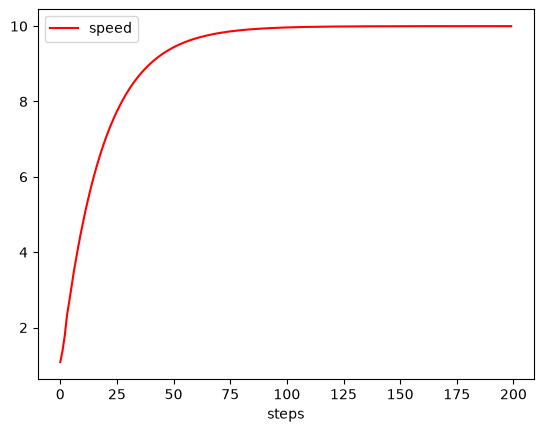

In [6]:

x = np.array([ 0., 0., 0.])

set_point = np.array([10., 10., 10.])

x_t = x - set_point

dps = ar.data.DataPlotter()
dps.set_x("steps")
dps.add_y("speed", "speed")

for t in range(0,200):
    u = - K @ x_t
    x_t = A @ x_t + B @ u
    x = x_t + set_point
    dps.append_x(t)
    dps.append_y("speed", x[0])

dps.plot()
